# Lecture 15: DBSCAN and hierarchical clustering

- **Compare:** apply K-means, DBSCAN, and hierarchical clustering to food image features.
- **Inspect:** examine cluster members and images labelled as noise.
- **Interpret:** connect parameter choices to the groups we discover.

**Predict:** Should every image have to belong to a cluster?

## Setup and imports

- Run cells in order using this directory's `.venv`, with `content/classes/varada` as the working directory.
- Dependencies: PyTorch, torchvision, scikit-learn, SciPy, NumPy, pandas, and Matplotlib (available in this directory's project environment).
- Use the same small food subset as lecture 14 in `data/food/`, with one subfolder per category for `ImageFolder`.
- Dataset source: [Food-101](https://www.kaggle.com/datasets/kmader/food41).
- The first feature-extraction run may download pretrained DenseNet weights and needs internet access.
- Keep the subset small: images are loaded into memory, and pairwise distances and hierarchical clustering use memory that grows quadratically with the number of images.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, fcluster, ward
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics.pairwise import euclidean_distances
from torchvision import datasets, models, transforms

%matplotlib inline
DATA_DIR = Path("data")
IMAGE_SIZE = 224
RANDOM_STATE = 123
plt.rcParams.update({"figure.figsize": (8, 4)})
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if not (DATA_DIR / "food").is_dir():
    raise FileNotFoundError(
        "Place the food image subset in data/food/, with one subfolder per category. "
        "Run from content/classes/varada."
    )

## 1. Inspect the images and extract features

- Reuse lecture 14's pretrained DenseNet representation; we are not training a neural network.
- Preserve image order so feature rows, labels, and displayed images stay aligned.
- Category labels are available for context but are not passed to the clustering algorithms.

In [2]:
def read_img_dataset(data_dir):
    """Load a small ImageFolder dataset as resized RGB tensors in [0, 1]."""
    image_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
    ])
    image_dataset = datasets.ImageFolder(data_dir, transform=image_transform)
    loader = torch.utils.data.DataLoader(
        image_dataset, batch_size=min(32, len(image_dataset)),
        shuffle=False, num_workers=0,
    )
    batches = list(loader)
    inputs = torch.cat([images for images, _ in batches])
    labels = torch.cat([labels for _, labels in batches])
    return inputs, labels, image_dataset.classes


def plot_sample_imgs(inputs, n_img=24, title="Sample images"):
    """Display RGB tensors without changing their row order."""
    n_img = min(n_img, len(inputs))
    n_cols = min(6, n_img)
    n_rows = (n_img + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, inputs[:n_img]):
        ax.imshow(image.permute(1, 2, 0).numpy())
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def get_cluster_images(model, inputs, cluster, n_img=6):
    """Display the first members of one cluster using matching feature/image rows."""
    indices = np.flatnonzero(model.labels_ == cluster)[:n_img]
    if len(indices) == 0:
        print(f"Cluster {cluster} has no images.")
        return
    plot_sample_imgs(inputs[indices], n_img=n_img, title=f"Cluster {cluster}")

350 images; source categories: ['beet_salad', 'chocolate_cake', 'edamame', 'french_fries', 'pizza', 'spring_rolls', 'sushi']


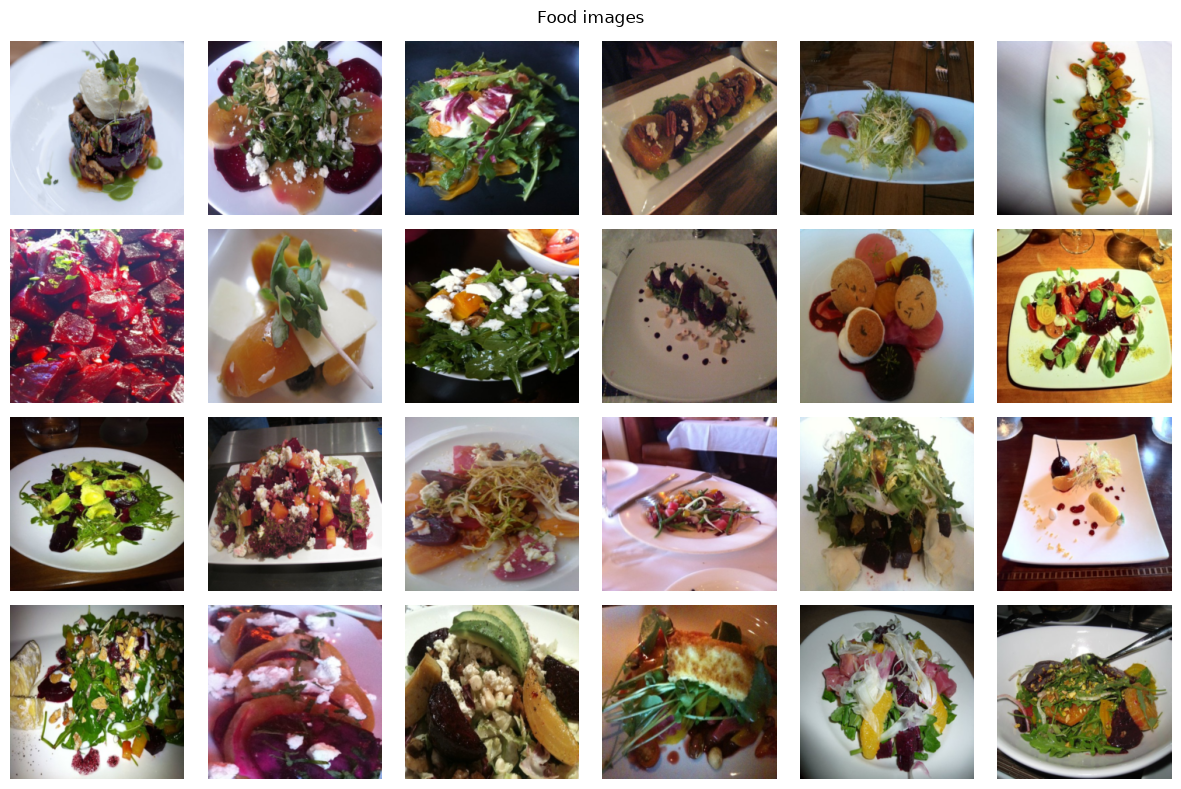

In [3]:
food_inputs, food_labels, food_categories = read_img_dataset(DATA_DIR / "food")
print(f"{len(food_inputs)} images; source categories: {food_categories}")
plot_sample_imgs(food_inputs, title="Food images")

In [4]:
weights = models.DenseNet121_Weights.IMAGENET1K_V1
feature_transform = weights.transforms()
densenet = models.densenet121(weights=weights)
densenet.classifier = torch.nn.Identity()
densenet.eval();

In [5]:
def get_features(model, inputs, batch_size=16):
    """Extract pretrained features in small CPU batches, preserving image order."""
    model.eval()
    features = []
    with torch.inference_mode():
        for batch in inputs.split(batch_size):
            prepared = feature_transform(batch)
            features.append(model(prepared).cpu())
    return torch.cat(features).numpy()


Z_food = get_features(densenet, food_inputs)
print(f"Feature matrix shape: {Z_food.shape}")

Feature matrix shape: (350, 1024)


## 2. Recall: K-means assigns every image

- Start with `k = 5`; this is an illustrative choice, not a known correct number of groups.
- Keep these features fixed as we change clustering methods.

**Predict:** Where will K-means put an image that looks unlike the others?

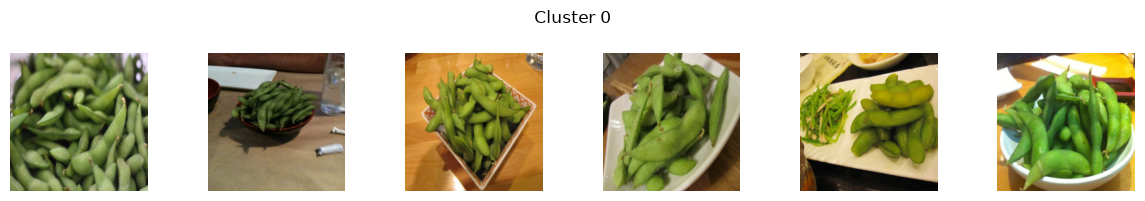

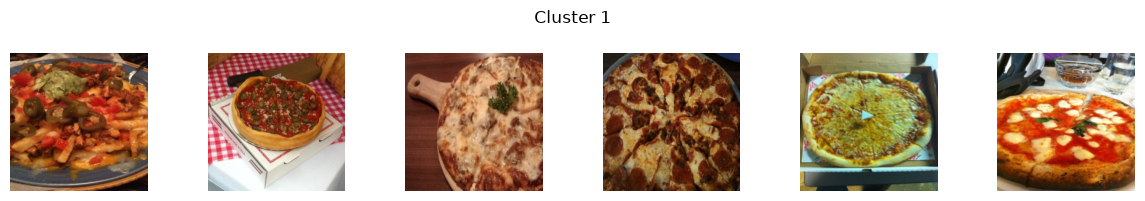

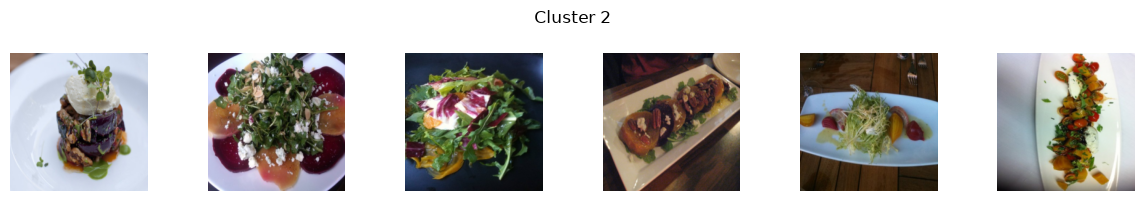

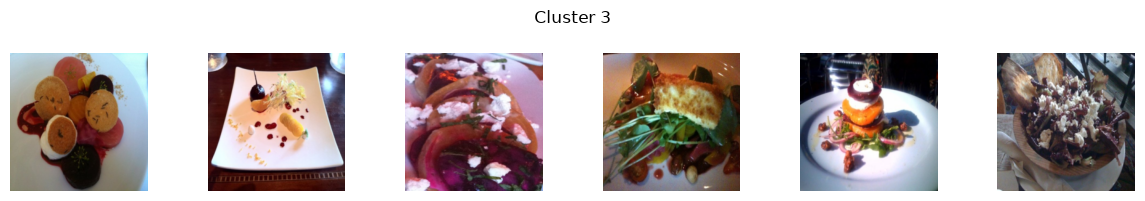

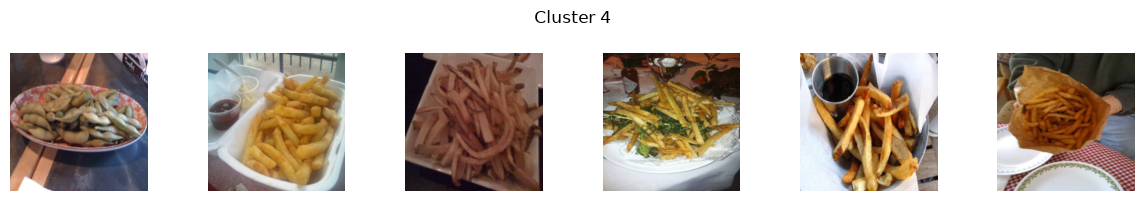

In [6]:
k = 5
km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
km.fit(Z_food)
for cluster in range(k):
    get_cluster_images(km, food_inputs, cluster)

## 3. DBSCAN: allow some images to remain unassigned

- `eps` is the neighbourhood radius in feature space.
- `min_samples` is the number of points needed in that neighbourhood for a **core point**, including the point itself.
- DBSCAN grows clusters through connected core points and includes neighbouring border points.
- Label `-1` means **noise**; it is not a cluster. Other label numbers are arbitrary identifiers.

**Predict:** Will the default `eps=0.5` be large enough for these pretrained features?

In [7]:
def clustering_summary(labels):
    """Summarize clusters separately from DBSCAN's noise label."""
    labels = np.asarray(labels)
    cluster_ids, sizes = np.unique(labels[labels != -1], return_counts=True)
    return {
        "clusters": len(cluster_ids),
        "noise_images": int(np.sum(labels == -1)),
        "noise_percent": round(100 * np.mean(labels == -1), 1),
        "cluster_sizes": sizes.tolist(),
    }


def show_groups(inputs, labels, n_img=6):
    """Show a few members per group, keeping noise separate."""
    for cluster in np.unique(labels):
        if cluster == -1:
            continue
        indices = np.flatnonzero(labels == cluster)
        plot_sample_imgs(
            inputs[indices[:n_img]], n_img=n_img,
            title=f"Cluster {cluster}: {len(indices)} images (showing up to {n_img})",
        )


default_labels = DBSCAN().fit_predict(Z_food)
display(pd.DataFrame([clustering_summary(default_labels)], index=["DBSCAN defaults"]))

,clusters,noise_images,noise_percent,cluster_sizes
DBSCAN defaults,0,350,100.0,[]


### Choose an `eps` range for these features

Inspect distances before choosing a radius. These are **all pairwise distances**, not nearest-neighbour distances; their summary gives scale, not an optimal `eps`.

We keep the raw pretrained features used in lecture 14. Scaling or changing the representation changes distances and requires revisiting `eps`.

In [8]:
distances = euclidean_distances(Z_food)
pairwise_distances = distances[np.triu_indices(len(Z_food), k=1)]
display(pd.Series(pairwise_distances, name="Pairwise Euclidean distance").describe())

count    61075.000000
mean        24.555988
std          3.048347
min         10.628177
25%         22.604178
50%         24.660662
75%         26.561758
max         37.522938
Name: Pairwise Euclidean distance, dtype: float64

### Brief tuning guidelines

- Start with `min_samples=5`, then explore `eps` while holding it fixed.
- **Mostly noise?** Try increasing `eps`; decreasing `min_samples` also relaxes the density requirement.
- **Large merged groups?** Try decreasing `eps`; increasing `min_samples` makes the core-point requirement stricter.
- Compare cluster sizes, noise percentage, and actual images. Fewer noise points does not automatically mean better groups.
- A single density threshold may struggle with groups of different densities. There may be no setting that gives the groups you want.

**Predict:** As `eps` increases, what will happen to the number of noise images? Must the number of clusters move in only one direction?

In [9]:
min_samples = 5
# Use the observed distance scale to choose a short illustrative sweep.
# These percentiles are starting points to inspect, not a tuning rule.
eps_values = np.unique(np.round(np.quantile(pairwise_distances, [0.001, 0.005, 0.01, 0.05]), 2))
results = []
for eps in eps_values:
    labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(Z_food)
    results.append({"eps": eps, "min_samples": min_samples, **clustering_summary(labels)})
display(pd.DataFrame(results))

,eps,min_samples,clusters,noise_images,noise_percent,cluster_sizes
0,14.62,5,2,328,93.7,"[14, 8]"
1,16.14,5,2,246,70.3,"[92, 12]"
2,16.99,5,3,193,55.1,"[127, 27, 3]"
3,19.36,5,1,97,27.7,[253]


### Inspect a candidate and its noise images

Choose a row from the table to inspect. The cell starts with the second radius as an example; change `eps` after reviewing the results. This is not an automatically selected best model.

,eps,clusters,noise_images,noise_percent,cluster_sizes
0,16.14,2,246,70.3,"[92, 12]"


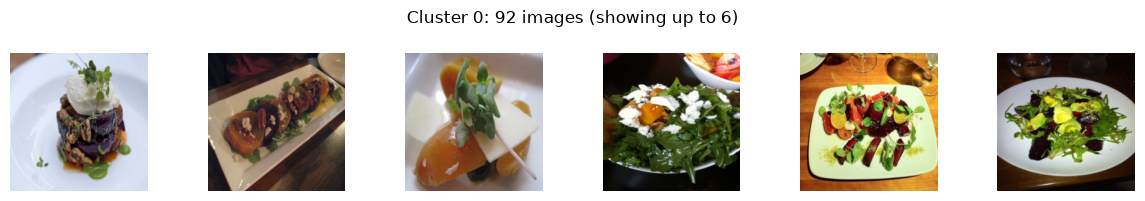

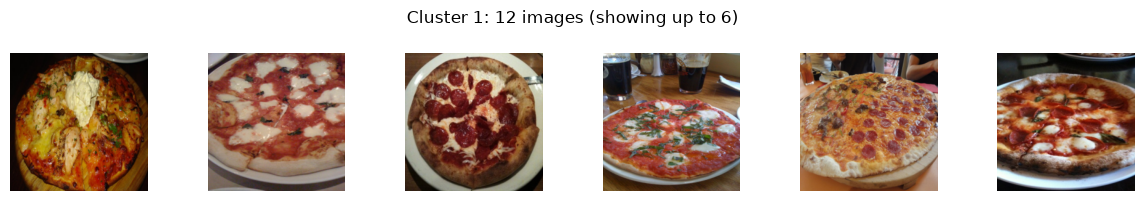

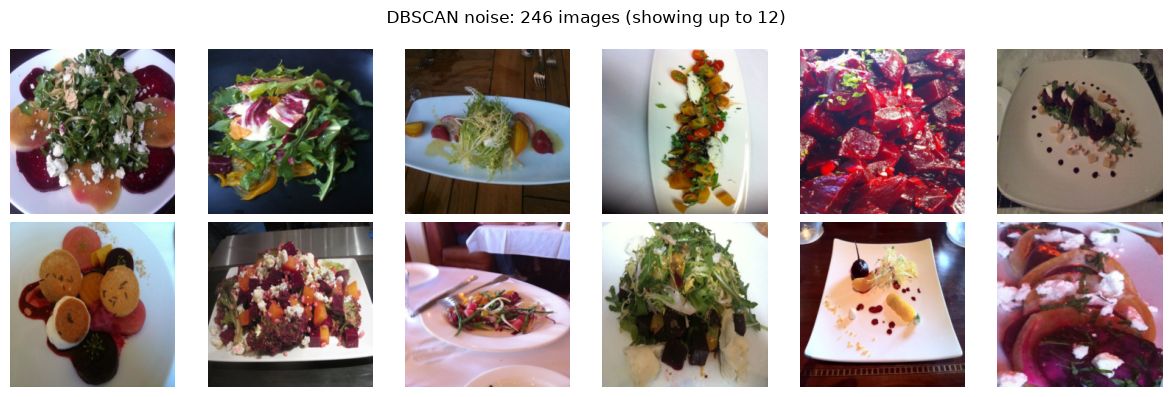

In [10]:
eps = float(eps_values[min(1, len(eps_values) - 1)])
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(Z_food)
display(pd.DataFrame([{"eps": eps, **clustering_summary(dbscan_labels)}]))
show_groups(food_inputs, dbscan_labels)

noise_indices = np.flatnonzero(dbscan_labels == -1)
if len(noise_indices):
    plot_sample_imgs(
        food_inputs[noise_indices[:12]], n_img=12,
        title=f"DBSCAN noise: {len(noise_indices)} images (showing up to 12)",
    )
else:
    print("No images were labelled as noise at this setting.")

**Discuss:** Does a noise label mean an image is incorrect or unusual to a person?

<details>
<summary>Reveal explanation</summary>

- Noise means the image was not assigned to a sufficiently dense group under this representation, distance metric, and parameter setting.
- It may be a perfectly ordinary food image with few nearby examples.
- With `min_samples` fixed, increasing `eps` cannot increase the number of noise points. The cluster count can rise as clusters form and fall as groups connect.
- Inspect more members before describing a whole cluster; the first few images may hide variation.

</details>

## 4. Hierarchical clustering: inspect groups at different resolutions

- Start with individual images and repeatedly merge groups using **Ward linkage**, which chooses the merge with the smallest increase in within-cluster sum of squared distances.
- The dendrogram records this merge hierarchy. Higher merges have a larger Ward linkage distance.
- Use the same Euclidean feature space as above.

**Predict:** What should happen to the groups when we cut the tree at a lower height?

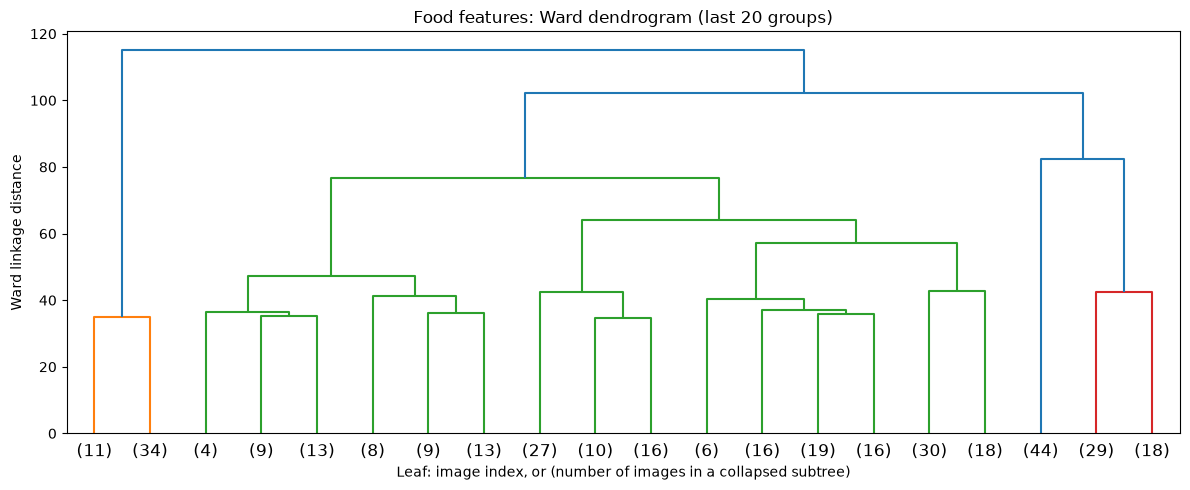

In [11]:
linkage_matrix = ward(Z_food)
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(
    linkage_matrix, truncate_mode="lastp", p=20,
    show_leaf_counts=True, no_labels=False, ax=ax,
)
ax.set_title("Food features: Ward dendrogram (last 20 groups)")
ax.set_xlabel("Leaf: image index, or (number of images in a collapsed subtree)")
ax.set_ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

### Compare two cluster counts

`criterion="maxclust"` requests **at most** the specified number of clusters. Cutting the same tree more finely reveals subgroups; it does not establish a correct number of food categories.

The displayed dendrogram is truncated for readability; its leaves can represent several images.

Requested at most 5 clusters; obtained 5.


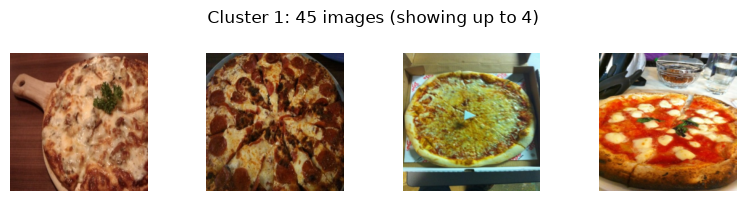

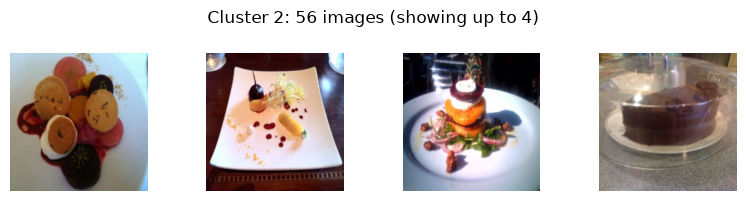

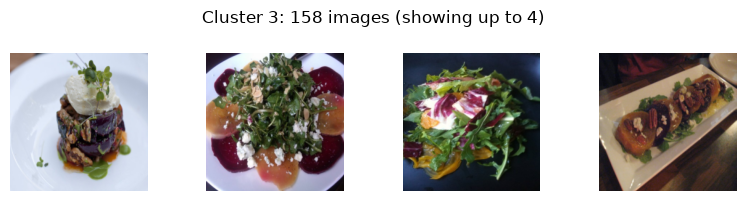

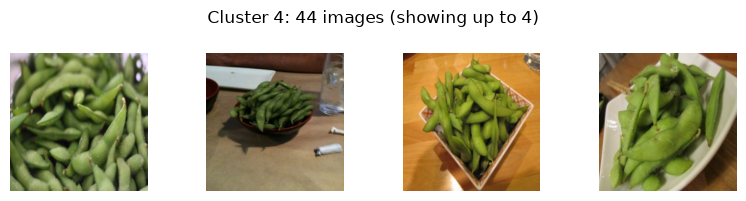

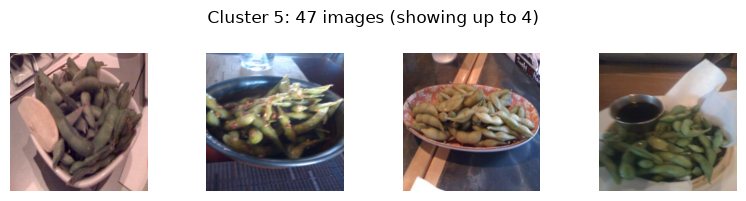

Requested at most 10 clusters; obtained 10.


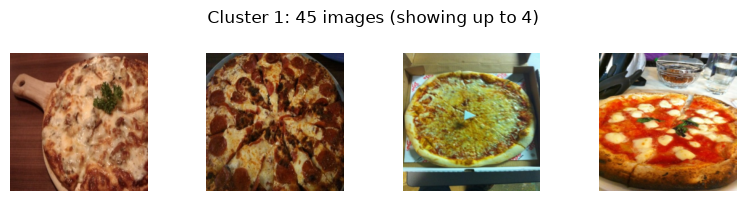

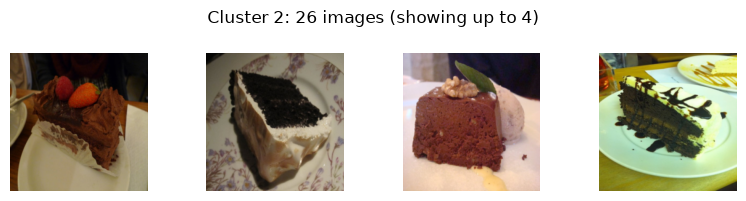

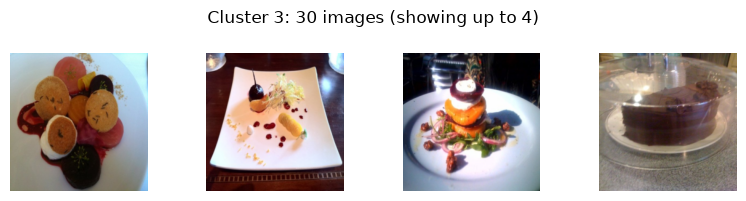

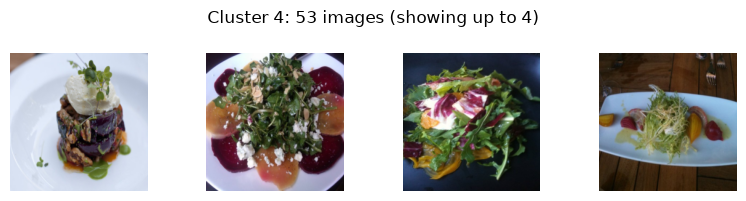

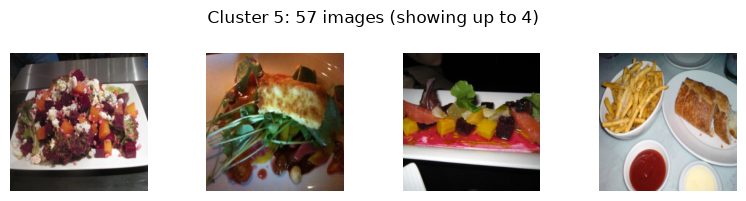

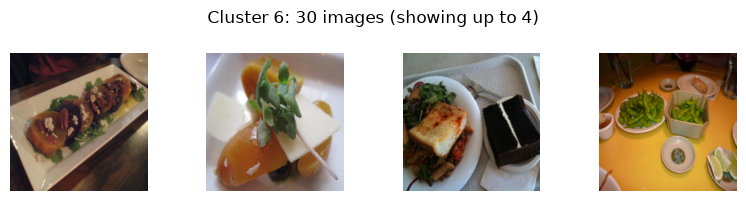

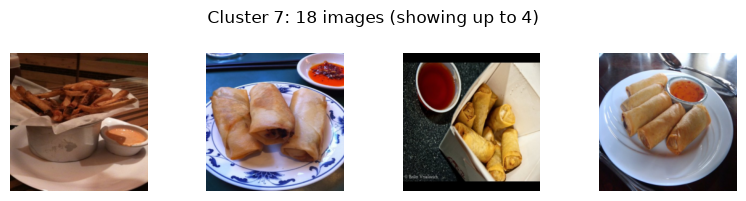

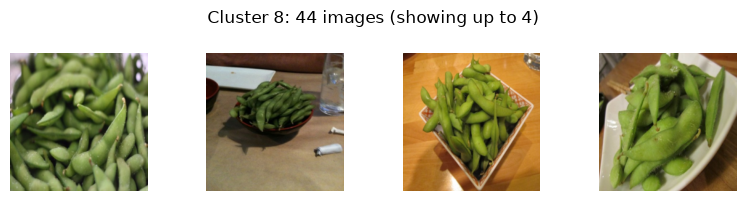

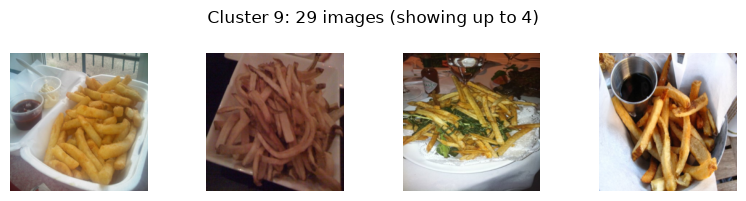

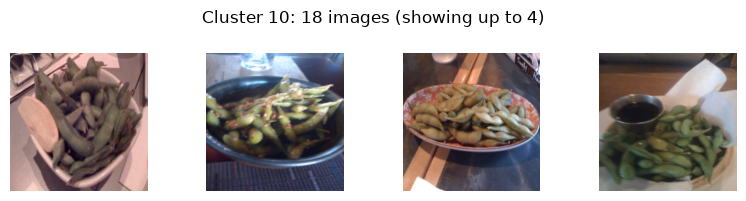

In [12]:
for requested_clusters in [5, 10]:
    hierarchical_labels = fcluster(
        linkage_matrix, t=requested_clusters, criterion="maxclust"
    )
    print(f"Requested at most {requested_clusters} clusters; "
          f"obtained {len(np.unique(hierarchical_labels))}.")
    show_groups(food_inputs, hierarchical_labels, n_img=4)

## 5. Check your interpretation

- How does DBSCAN differ from K-means in assigning images to groups?
- If nearly every image is noise, which parameter would you change first, and in which direction?
- Does a dendrogram merge height measure classification accuracy?
- Why might all three methods produce groups that mix food categories?

<details>
<summary>Reveal answers</summary>

- K-means assigns every image to one of the requested clusters. DBSCAN discovers density-connected groups and can leave images as noise.
- Try a larger `eps` with `min_samples` fixed, then inspect the result. Lowering `min_samples` is another way to relax the density requirement.
- No. It records the linkage distance of a merge. A lower cut generally produces more groups; a higher cut combines groups.
- These methods use feature-space distances, not category labels. Backgrounds, ingredients, views, and the feature representation can all affect the groups.

</details>

**Takeaway:** Choose a representation and clustering method that fit your goal, then inspect the groups. Cluster IDs are not food category labels, and a parameter setting alone does not establish that a clustering is useful.